In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib
import warnings

warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


Load dataset

In [2]:
import os

csv_path = "../dataset/ballistics_500.csv"
if not os.path.exists(csv_path):
    for candidate in ["../data/ballistics_500.csv", "data/ballistics_500.csv", "ballistics_500.csv", "../ballistics_500.csv"]:
        if os.path.exists(candidate):
            csv_path = candidate
            break

df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Shape: (500, 12)


,Cartridge,Type,Weight,BC,V0,V100,V200,E0,E100,E200,BD100,BD200
0,44-40 WINCHESTER,Handgun,345,NaN,1669,1150,NaN,2134,1013,NaN,0.5,NaN
1,460 WEATHERBY MAGNUM,Rifle,410,0.450,2117,1865,1623.0,4081,3167,2399.0,-3.2,-9.5
2,38-40 WINCHESTER,Handgun,135,NaN,1381,1048,NaN,572,329,NaN,4.6,NaN
3,6MM REMINGTON,Rifle,65,0.145,3136,2629,2292.0,1420,998,758.0,-1.3,-1.3
4,44 RUSSIAN,Handgun,125,NaN,910,720,NaN,230,144,NaN,15.3,NaN


In [3]:
import os

csv_path = "../dataset/ballistics_500.csv"
if not os.path.exists(csv_path):
    for candidate in ["../data/ballistics_500.csv", "data/ballistics_500.csv", "ballistics_500.csv", "../ballistics_500.csv"]:
        if os.path.exists(candidate):
            csv_path = candidate
            break

df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Shape: (500, 12)


,Cartridge,Type,Weight,BC,V0,V100,V200,E0,E100,E200,BD100,BD200
0,44-40 WINCHESTER,Handgun,345,NaN,1669,1150,NaN,2134,1013,NaN,0.5,NaN
1,460 WEATHERBY MAGNUM,Rifle,410,0.450,2117,1865,1623.0,4081,3167,2399.0,-3.2,-9.5
2,38-40 WINCHESTER,Handgun,135,NaN,1381,1048,NaN,572,329,NaN,4.6,NaN
3,6MM REMINGTON,Rifle,65,0.145,3136,2629,2292.0,1420,998,758.0,-1.3,-1.3
4,44 RUSSIAN,Handgun,125,NaN,910,720,NaN,230,144,NaN,15.3,NaN


Missing values

In [4]:
missing = pd.DataFrame({
    "Column": df.columns,
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

display(missing)

,Column,Missing Values,Missing Percentage
Cartridge,Cartridge,0,0.0
Type,Type,0,0.0
Weight,Weight,0,0.0
BC,BC,253,50.6
V0,V0,0,0.0
V100,V100,0,0.0
V200,V200,253,50.6
E0,E0,0,0.0
E100,E100,0,0.0
E200,E200,253,50.6


In [5]:
display(df.describe(include="all"))

,Cartridge,Type,Weight,BC,V0,V100,V200,E0,E100,E200,BD100,BD200
count,500,500,500.000000,247.000000,500.000000,500.000000,247.000000,500.000000,500.000000,247.000000,500.000000,247.000000
unique,122,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,30 LUGER,Rifle,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,14,247,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,185.626000,0.271826,1966.660000,1631.168000,2141.623482,1729.768000,1282.626000,1803.619433,4.905800,-5.038170
std,NaN,NaN,135.721726,0.107030,875.662047,858.216191,363.908447,1480.639232,1200.887527,652.234066,7.708176,2.828353
min,NaN,NaN,16.000000,0.145000,650.000000,418.000000,1332.000000,56.000000,24.000000,589.000000,-4.800000,-12.200000
25%,NaN,NaN,100.000000,0.201500,1129.000000,796.250000,1964.500000,387.000000,196.000000,1312.000000,-1.400000,-6.450000
50%,NaN,NaN,160.000000,0.250000,1850.000000,1387.000000,2226.000000,1284.500000,917.500000,1774.000000,0.550000,-4.300000
75%,NaN,NaN,215.000000,0.312000,2877.000000,2525.250000,2396.500000,2960.500000,2292.250000,2173.500000,11.700000,-3.107012


for numeric only

In [6]:
display(df.describe())

,Weight,BC,V0,V100,V200,E0,E100,E200,BD100,BD200
count,500.000000,247.000000,500.000000,500.000000,247.000000,500.000000,500.000000,247.000000,500.000000,247.000000
mean,185.626000,0.271826,1966.660000,1631.168000,2141.623482,1729.768000,1282.626000,1803.619433,4.905800,-5.038170
std,135.721726,0.107030,875.662047,858.216191,363.908447,1480.639232,1200.887527,652.234066,7.708176,2.828353
min,16.000000,0.145000,650.000000,418.000000,1332.000000,56.000000,24.000000,589.000000,-4.800000,-12.200000
25%,100.000000,0.201500,1129.000000,796.250000,1964.500000,387.000000,196.000000,1312.000000,-1.400000,-6.450000
50%,160.000000,0.250000,1850.000000,1387.000000,2226.000000,1284.500000,917.500000,1774.000000,0.550000,-4.300000
75%,215.000000,0.312000,2877.000000,2525.250000,2396.500000,2960.500000,2292.250000,2173.500000,11.700000,-3.107012
max,740.000000,0.601000,3439.000000,3129.000000,2801.000000,5625.000000,4644.000000,3644.000000,24.700000,-0.200000


Check categories

In [7]:
print("Cartridge categories:")
print(df["Cartridge"].nunique())

print("\nType categories:")
print(df["Type"].unique())

print("\nType distribution:")
print(df["Type"].value_counts())

Cartridge categories:
122

Type categories:
['Handgun' 'Rifle' 'Rimfire']

Type distribution:
Type
Rifle      247
Handgun    230
Rimfire     23
Name: count, dtype: int64


In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


EDA: Type distribution

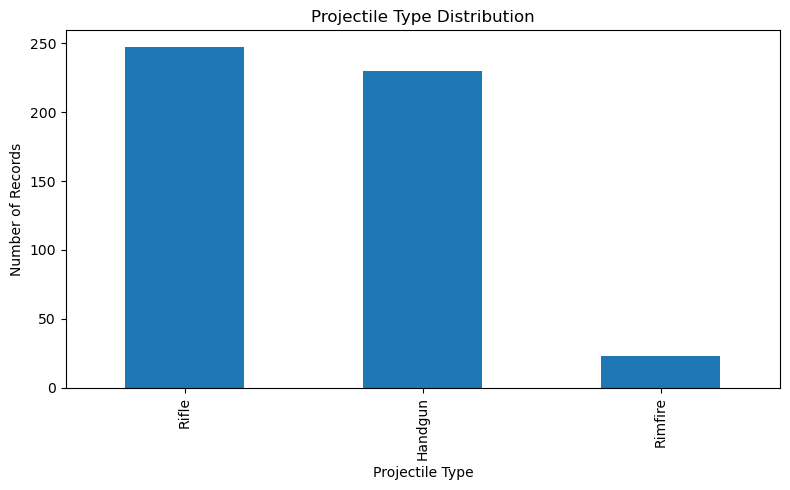

In [9]:
plt.figure(figsize=(8, 5))

df["Type"].value_counts().plot(kind="bar")

plt.title("Projectile Type Distribution")
plt.xlabel("Projectile Type")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

V0 distribution

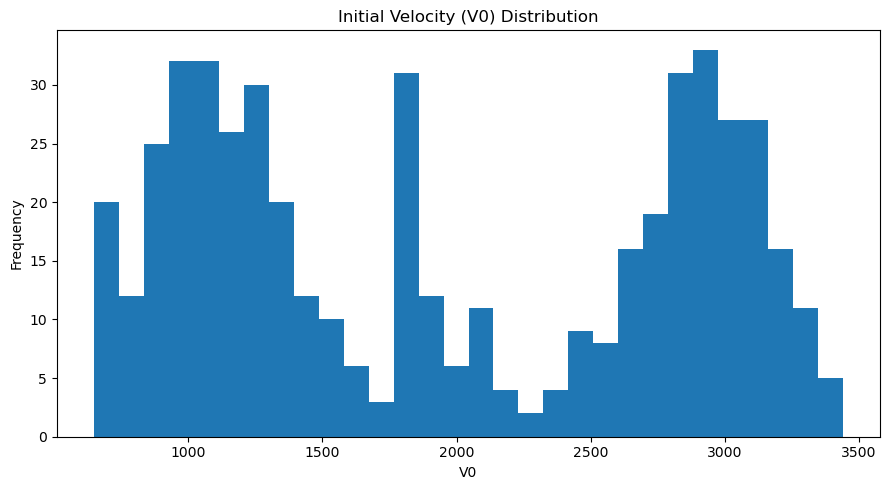

In [10]:
plt.figure(figsize=(9, 5))

plt.hist(df["V0"], bins=30)

plt.title("Initial Velocity (V0) Distribution")
plt.xlabel("V0")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

Weight distribution

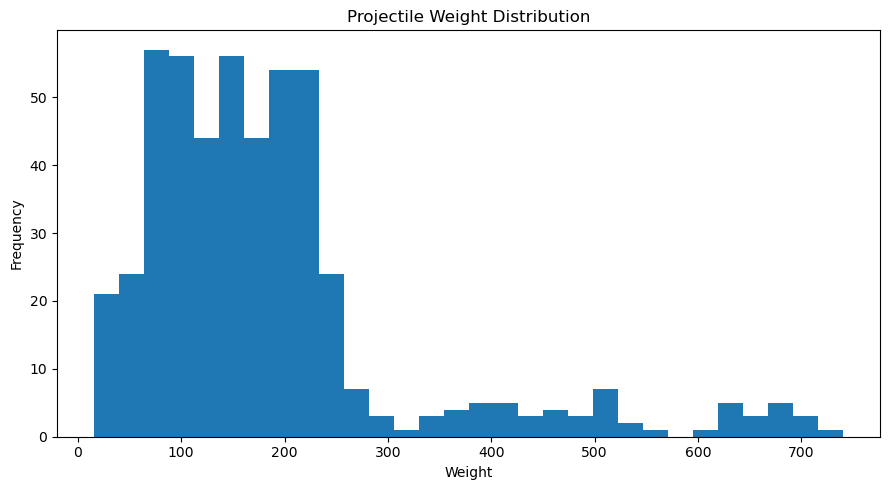

In [11]:
plt.figure(figsize=(9, 5))

plt.hist(df["Weight"], bins=30)

plt.title("Projectile Weight Distribution")
plt.xlabel("Weight")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

V0 vs V100

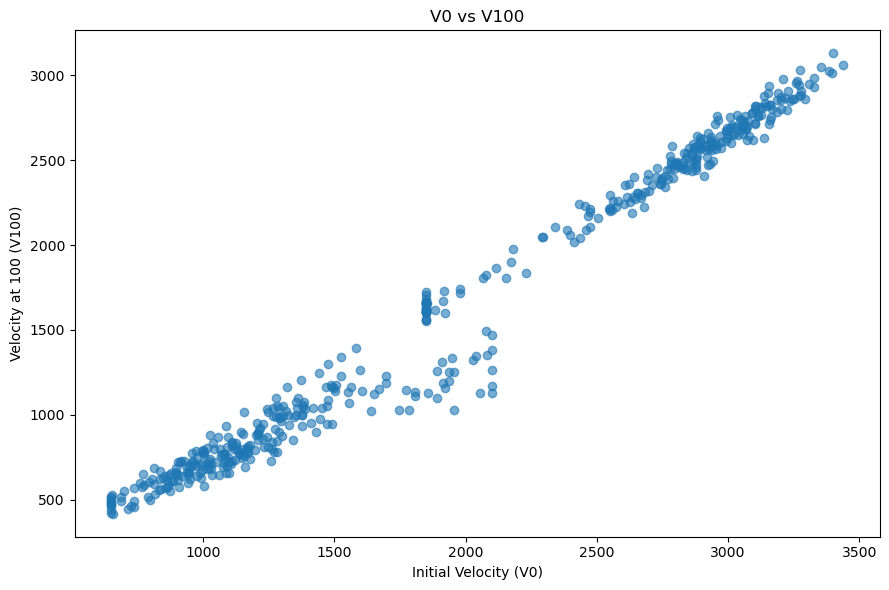

In [12]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["V0"],
    df["V100"],
    alpha=0.6
)

plt.xlabel("Initial Velocity (V0)")
plt.ylabel("Velocity at 100 (V100)")
plt.title("V0 vs V100")

plt.tight_layout()
plt.show()

Weight vs E100

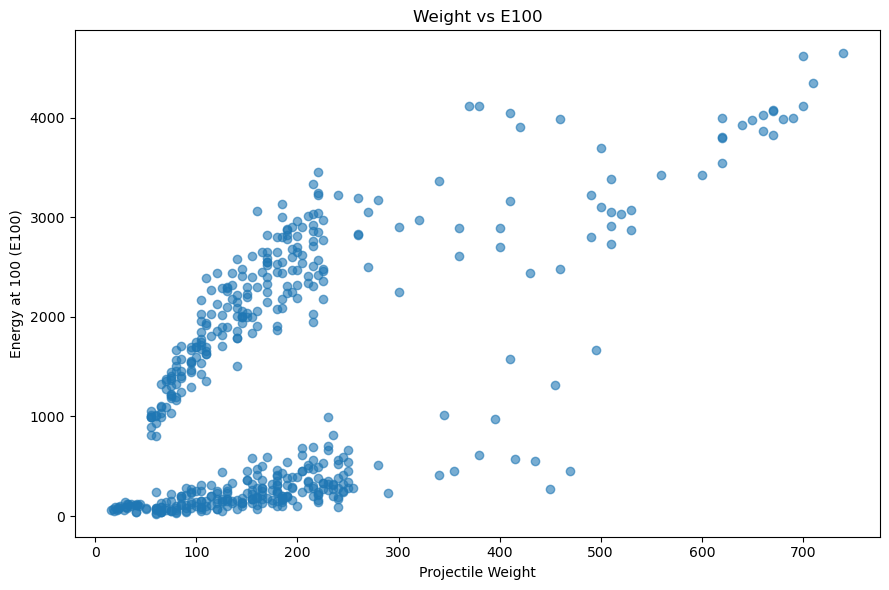

In [13]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["Weight"],
    df["E100"],
    alpha=0.6
)

plt.xlabel("Projectile Weight")
plt.ylabel("Energy at 100 (E100)")
plt.title("Weight vs E100")

plt.tight_layout()
plt.show()

V0 vs BD100

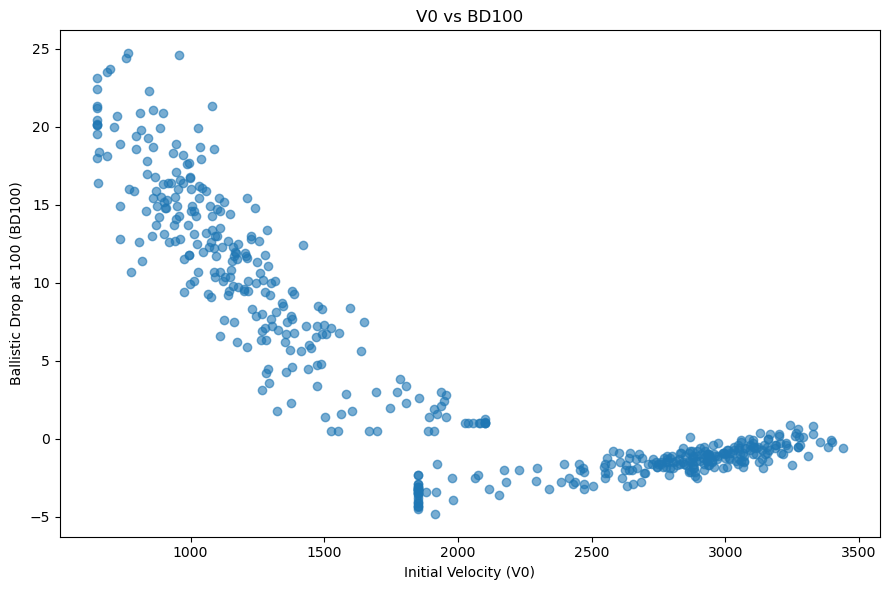

In [14]:
plt.figure(figsize=(9, 6))

plt.scatter(
    df["V0"],
    df["BD100"],
    alpha=0.6
)

plt.xlabel("Initial Velocity (V0)")
plt.ylabel("Ballistic Drop at 100 (BD100)")
plt.title("V0 vs BD100")

plt.tight_layout()
plt.show()

Correlation matrix

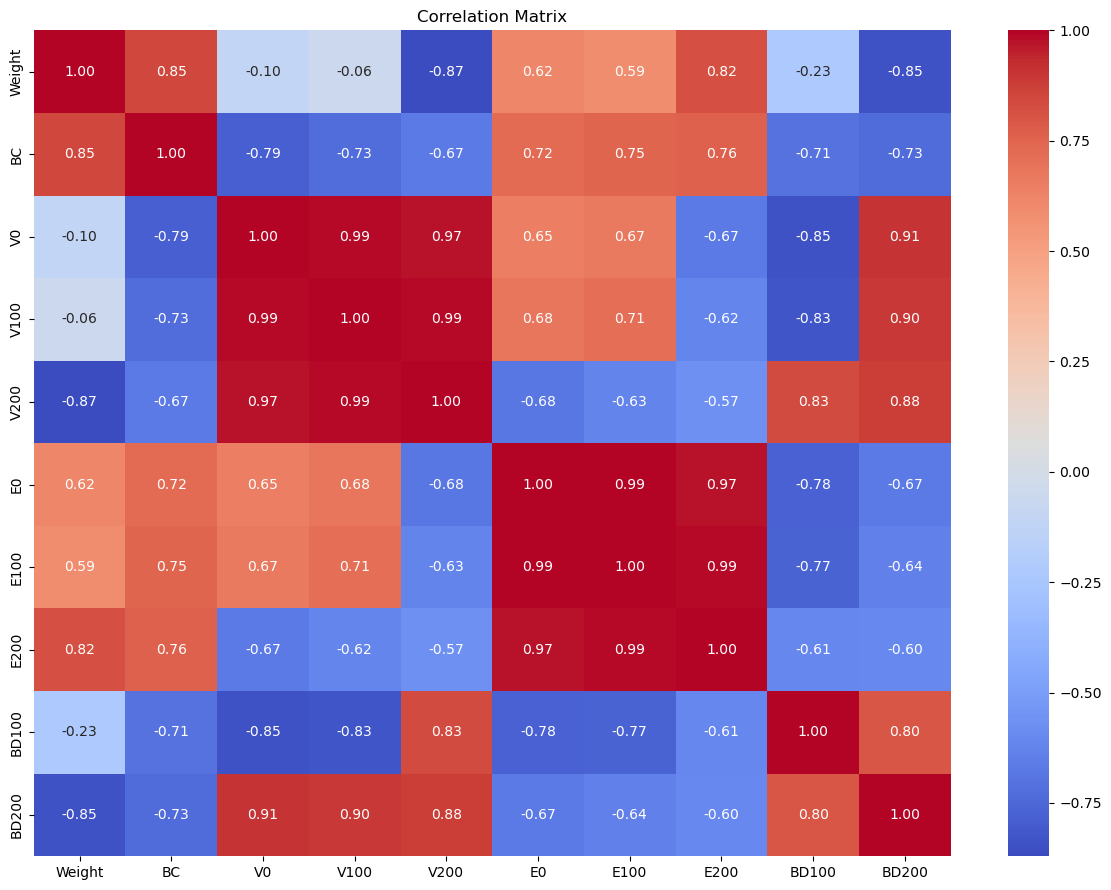

In [15]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 9))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()

Prepare V100 dataset

In [16]:
# Explicitly select V100 target and remove missing target values
target_v100 = "V100"
df_v100 = df.dropna(subset=[target_v100]).copy()

# Exclude all six target columns to prevent target leakage
target_columns = ["V100", "V200", "E100", "E200", "BD100", "BD200"]
features_100 = [
    "Cartridge",
    "Type",
    "Weight",
    "BC",
    "V0"
]
features_v100 = [col for col in features_100 if col not in target_columns]

# Dedicated feature DataFrame and target Series
X_v100 = df_v100[features_v100]
y_v100 = df_v100[target_v100]

# Preserve generic aliases for earlier notebook cells
target_100 = target_v100
X = X_v100
y = y_v100

print("Features:")
print(features_v100)

print("\nTarget:")
print(target_v100)

print("\nX_v100 shape:", X_v100.shape)
print("y_v100 shape:", y_v100.shape)


Features:
['Cartridge', 'Type', 'Weight', 'BC', 'V0']

Target:
V100

X_v100 shape: (500, 5)
y_v100 shape: (500,)


Define categorical and numerical columns

In [17]:
categorical_features = [
    "Cartridge",
    "Type"
]

numerical_features = [
    "Weight",
    "BC",
    "V0"
]

Preprocessing pipeline

In [19]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

Train/test split

In [20]:
X_train_v100, X_test_v100, y_train_v100, y_test_v100 = train_test_split(
    X_v100,
    y_v100,
    test_size=0.20,
    random_state=42
)

# Aliases for original evaluation cells
X_train, X_test, y_train, y_test = X_train_v100, X_test_v100, y_train_v100, y_test_v100

print("Training rows:", len(X_train_v100))
print("Testing rows:", len(X_test_v100))


Training rows: 400
Testing rows: 100


Linear Regression

In [22]:
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

In [23]:
linear_mae = mean_absolute_error(y_test, linear_pred)
linear_mse = mean_squared_error(y_test, linear_pred)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(y_test, linear_pred)

print("Linear Regression")
print("-------------------------")
print("MAE :", linear_mae)
print("MSE :", linear_mse)
print("RMSE:", linear_rmse)
print("R²  :", linear_r2)

Linear Regression
-------------------------
MAE : 3002841153936.9
MSE : 4.508527497675045e+26
RMSE: 21233293427245.44
R²  : -6.109965718590753e+20


Decision Tree

In [24]:
tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(
        max_depth=10,
        random_state=42
    ))
])

tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)

In [25]:
tree_mae = mean_absolute_error(y_test, tree_pred)
tree_mse = mean_squared_error(y_test, tree_pred)
tree_rmse = np.sqrt(tree_mse)
tree_r2 = r2_score(y_test, tree_pred)

print("Decision Tree")
print("-------------------------")
print("MAE :", tree_mae)
print("MSE :", tree_mse)
print("RMSE:", tree_rmse)
print("R²  :", tree_r2)

Decision Tree
-------------------------
MAE : 74.92456135893093
MSE : 10122.990660924896
RMSE: 100.61307400594067
R²  : 0.9862813022789013


Random Forest

In [26]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=15,
        min_samples_split=3,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

In [28]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest")
print("-------------------------")
print("MAE :", rf_mae)
print("MSE :", rf_mse)
print("RMSE:", rf_rmse)
print("R²  :", rf_r2)

Random Forest
-------------------------
MAE : 63.29636815699869
MSE : 6512.789943297351
RMSE: 80.70185836334471
R²  : 0.9911738537013581


Gradient Boosting

In [29]:
gb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)

gb_pred = gb_model.predict(X_test)

In [30]:
gb_mae = mean_absolute_error(y_test, gb_pred)
gb_mse = mean_squared_error(y_test, gb_pred)
gb_rmse = np.sqrt(gb_mse)
gb_r2 = r2_score(y_test, gb_pred)

print("Gradient Boosting")
print("-------------------------")
print("MAE :", gb_mae)
print("MSE :", gb_mse)
print("RMSE:", gb_rmse)
print("R²  :", gb_r2)

Gradient Boosting
-------------------------
MAE : 60.39159831998204
MSE : 5800.196201669733
RMSE: 76.1590191748143
R²  : 0.9921395622026088


Compare models

In [31]:
results_v100 = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],

    "MAE": [
        linear_mae,
        tree_mae,
        rf_mae,
        gb_mae
    ],

    "MSE": [
        linear_mse,
        tree_mse,
        rf_mse,
        gb_mse
    ],

    "RMSE": [
        linear_rmse,
        tree_rmse,
        rf_rmse,
        gb_rmse
    ],

    "R2": [
        linear_r2,
        tree_r2,
        rf_r2,
        gb_r2
    ]
})

results_v100 = results_v100.sort_values(
    "RMSE"
)


display(results_v100)

,Model,MAE,MSE,RMSE,R2
3,Gradient Boosting,6.039160e+01,5.800196e+03,7.615902e+01,9.921396e-01
2,Random Forest,6.329637e+01,6.512790e+03,8.070186e+01,9.911739e-01
1,Decision Tree,7.492456e+01,1.012299e+04,1.006131e+02,9.862813e-01
0,Linear Regression,3.002841e+12,4.508527e+26,2.123329e+13,-6.109966e+20


5-Fold Cross Validation

In [32]:
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [33]:
rf_cv = cross_val_score(
    rf_model,
    X,
    y,
    cv=kf,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

rf_cv_rmse = -rf_cv

print("Random Forest 5-Fold CV RMSE:")
print(rf_cv_rmse)

print("\nMean CV RMSE:", rf_cv_rmse.mean())
print("Standard Deviation:", rf_cv_rmse.std())

Random Forest 5-Fold CV RMSE:
[80.74467701 64.61414454 85.06803547 79.58614058 76.8737432 ]

Mean CV RMSE: 77.37734816053293
Standard Deviation: 6.906769480383881


In [34]:
models = {
    "Linear Regression": linear_model,
    "Decision Tree": tree_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model
}

cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X,
        y,
        cv=kf,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    rmse_scores = -scores

    cv_results.append({
        "Model": name,
        "Mean CV RMSE": rmse_scores.mean(),
        "CV Std": rmse_scores.std()
    })

cv_results = pd.DataFrame(cv_results)

cv_results = cv_results.sort_values(
    "Mean CV RMSE"
)

display(cv_results)

,Model,Mean CV RMSE,CV Std
3,Gradient Boosting,7.591543e+01,3.415665e+00
2,Random Forest,7.737735e+01,6.906769e+00
1,Decision Tree,9.734723e+01,9.760891e+00
0,Linear Regression,1.368457e+13,1.109087e+13


Prediction 2 — E100

In [35]:
X_e100 = df[features_100]
y_e100 = df["E100"]

X_train_e100, X_test_e100, y_train_e100, y_test_e100 = train_test_split(
    X_e100,
    y_e100,
    test_size=0.20,
    random_state=42
)

e100_models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=10,
        random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=15,
        min_samples_split=3,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

e100_results = []

for name, algorithm in e100_models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", algorithm)
    ])

    pipeline.fit(
        X_train_e100,
        y_train_e100
    )

    prediction = pipeline.predict(X_test_e100)

    mae = mean_absolute_error(
        y_test_e100,
        prediction
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test_e100,
            prediction
        )
    )

    r2 = r2_score(
        y_test_e100,
        prediction
    )

    e100_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

e100_results = pd.DataFrame(e100_results)

display(
    e100_results.sort_values("RMSE")
)

,Model,MAE,RMSE,R2
2,Random Forest,1.135819e+02,1.754588e+02,9.790073e-01
1,Decision Tree,1.315923e+02,1.959555e+02,9.738161e-01
3,Gradient Boosting,1.325456e+02,1.975778e+02,9.733808e-01
0,Linear Regression,3.326192e+13,2.351973e+14,-3.772102e+22


Prediction 3 — BD100

In [36]:
X_bd100 = df[features_100]
y_bd100 = df["BD100"]

X_train_bd100, X_test_bd100, y_train_bd100, y_test_bd100 = train_test_split(
    X_bd100,
    y_bd100,
    test_size=0.20,
    random_state=42
)

bd100_results = []

for name, algorithm in e100_models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", algorithm)
    ])

    pipeline.fit(
        X_train_bd100,
        y_train_bd100
    )

    prediction = pipeline.predict(X_test_bd100)

    mae = mean_absolute_error(
        y_test_bd100,
        prediction
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test_bd100,
            prediction
        )
    )

    r2 = r2_score(
        y_test_bd100,
        prediction
    )

    bd100_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

bd100_results = pd.DataFrame(bd100_results)

display(
    bd100_results.sort_values("RMSE")
)

,Model,MAE,RMSE,R2
3,Gradient Boosting,1.376080e+00,2.041640e+00,9.179347e-01
2,Random Forest,1.353332e+00,2.118406e+00,9.116474e-01
1,Decision Tree,1.923879e+00,3.034251e+00,8.187391e-01
0,Linear Regression,6.494783e+11,4.592505e+12,-4.152413e+23


Prepare V200 data

In [37]:
df_v200 = df.dropna(subset=["V200"]).copy()

print("Rows available for V200:", len(df_v200))

Rows available for V200: 247


V200 model

In [38]:
X_v200 = df_v200[features_100]
y_v200 = df_v200["V200"]

X_train_v200, X_test_v200, y_train_v200, y_test_v200 = train_test_split(
    X_v200,
    y_v200,
    test_size=0.20,
    random_state=42
)

v200_results = []

v200_models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=10,
        random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=15,
        min_samples_split=3,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

for name, algorithm in v200_models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", algorithm)
    ])

    pipeline.fit(
        X_train_v200,
        y_train_v200
    )

    prediction = pipeline.predict(X_test_v200)

    v200_results.append({
        "Model": name,
        "MAE": mean_absolute_error(
            y_test_v200,
            prediction
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_test_v200,
                prediction
            )
        ),
        "R2": r2_score(
            y_test_v200,
            prediction
        )
    })

v200_results = pd.DataFrame(v200_results)

display(
    v200_results.sort_values("RMSE")
)

,Model,MAE,RMSE,R2
3,Gradient Boosting,55.458207,68.941115,0.954522
2,Random Forest,59.183282,73.602583,0.948164
0,Linear Regression,60.823697,74.602517,0.946746
1,Decision Tree,67.623000,87.305198,0.927067


BD200 model

In [39]:
df_bd200 = df.dropna(subset=["BD200"]).copy()

print("Rows available for BD200:", len(df_bd200))

X_bd200 = df_bd200[features_100]
y_bd200 = df_bd200["BD200"]

X_train_bd200, X_test_bd200, y_train_bd200, y_test_bd200 = train_test_split(
    X_bd200,
    y_bd200,
    test_size=0.20,
    random_state=42
)

bd200_results = []

for name, algorithm in v200_models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", algorithm)
    ])

    pipeline.fit(
        X_train_bd200,
        y_train_bd200
    )

    prediction = pipeline.predict(X_test_bd200)

    bd200_results.append({
        "Model": name,
        "MAE": mean_absolute_error(
            y_test_bd200,
            prediction
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_test_bd200,
                prediction
            )
        ),
        "R2": r2_score(
            y_test_bd200,
            prediction
        )
    })

bd200_results = pd.DataFrame(bd200_results)

display(
    bd200_results.sort_values("RMSE")
)

Rows available for BD200: 247


,Model,MAE,RMSE,R2
3,Gradient Boosting,1.052686,1.310847,0.769406
0,Linear Regression,1.085830,1.332884,0.761588
1,Decision Tree,1.102162,1.372526,0.747195
2,Random Forest,1.082704,1.387533,0.741637


Final model comparison

In [42]:
print("df exists:", "df" in globals())
print("preprocessor exists:", "preprocessor" in globals())
print("v200_models exists:", "v200_models" in globals())

df exists: True
preprocessor exists: True
v200_models exists: True


In [43]:
# =========================
# E200 MODEL
# =========================

# Keep only rows where E200 is available
df_e200 = df.dropna(subset=["E200"]).copy()

print("Rows available for E200:", len(df_e200))

# Features
features_100 = [
    "Cartridge",
    "Type",
    "Weight",
    "BC",
    "V0"
]

X_e200 = df_e200[features_100]
y_e200 = df_e200["E200"]

# Train-test split
X_train_e200, X_test_e200, y_train_e200, y_test_e200 = train_test_split(
    X_e200,
    y_e200,
    test_size=0.20,
    random_state=42
)

# Models
e200_models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=10,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=15,
        min_samples_split=3,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

# Store results
e200_results = []

for name, algorithm in e200_models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", algorithm)
    ])

    pipeline.fit(
        X_train_e200,
        y_train_e200
    )

    prediction = pipeline.predict(X_test_e200)

    mae = mean_absolute_error(
        y_test_e200,
        prediction
    )

    mse = mean_squared_error(
        y_test_e200,
        prediction
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_test_e200,
        prediction
    )

    e200_results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

# Convert to DataFrame
e200_results = pd.DataFrame(e200_results)

# Sort by RMSE
e200_results = e200_results.sort_values(
    "RMSE"
).reset_index(drop=True)

print("\nE200 MODEL RESULTS")
print("========================")

display(e200_results)

Rows available for E200: 247

E200 MODEL RESULTS


,Model,MAE,MSE,RMSE,R2
0,Gradient Boosting,141.755162,38615.465862,196.508183,0.934335
1,Random Forest,156.521901,43139.970822,207.701639,0.926641
2,Decision Tree,204.043561,77234.870639,277.911624,0.868664
3,Linear Regression,341.754904,171746.817917,414.423477,0.707948


In [44]:
# =========================
# BD200 MODEL
# =========================

df_bd200 = df.dropna(subset=["BD200"]).copy()

print("Rows available for BD200:", len(df_bd200))

X_bd200 = df_bd200[features_100]
y_bd200 = df_bd200["BD200"]

X_train_bd200, X_test_bd200, y_train_bd200, y_test_bd200 = train_test_split(
    X_bd200,
    y_bd200,
    test_size=0.20,
    random_state=42
)

bd200_results = []

for name, algorithm in e200_models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", algorithm)
    ])

    pipeline.fit(
        X_train_bd200,
        y_train_bd200
    )

    prediction = pipeline.predict(X_test_bd200)

    mae = mean_absolute_error(
        y_test_bd200,
        prediction
    )

    mse = mean_squared_error(
        y_test_bd200,
        prediction
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_test_bd200,
        prediction
    )

    bd200_results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

bd200_results = pd.DataFrame(bd200_results)

bd200_results = bd200_results.sort_values(
    "RMSE"
).reset_index(drop=True)

print("\nBD200 MODEL RESULTS")
print("========================")

display(bd200_results)

Rows available for BD200: 247

BD200 MODEL RESULTS


,Model,MAE,MSE,RMSE,R2
0,Gradient Boosting,1.052686,1.718320,1.310847,0.769406
1,Linear Regression,1.085830,1.776581,1.332884,0.761588
2,Decision Tree,1.102162,1.883827,1.372526,0.747195
3,Random Forest,1.082704,1.925249,1.387533,0.741637


In [45]:
print("========== V100 ==========")
display(results_v100)

print("\n========== E100 ==========")
display(e100_results.sort_values("RMSE"))

print("\n========== BD100 ==========")
display(bd100_results.sort_values("RMSE"))

print("\n========== V200 ==========")
display(v200_results.sort_values("RMSE"))

print("\n========== E200 ==========")
display(e200_results.sort_values("RMSE"))

print("\n========== BD200 ==========")
display(bd200_results.sort_values("RMSE"))

========== V100 ==========


,Model,MAE,MSE,RMSE,R2
3,Gradient Boosting,6.039160e+01,5.800196e+03,7.615902e+01,9.921396e-01
2,Random Forest,6.329637e+01,6.512790e+03,8.070186e+01,9.911739e-01
1,Decision Tree,7.492456e+01,1.012299e+04,1.006131e+02,9.862813e-01
0,Linear Regression,3.002841e+12,4.508527e+26,2.123329e+13,-6.109966e+20



========== E100 ==========


,Model,MAE,RMSE,R2
2,Random Forest,1.135819e+02,1.754588e+02,9.790073e-01
1,Decision Tree,1.315923e+02,1.959555e+02,9.738161e-01
3,Gradient Boosting,1.325456e+02,1.975778e+02,9.733808e-01
0,Linear Regression,3.326192e+13,2.351973e+14,-3.772102e+22



========== BD100 ==========


...

,Model,MAE,RMSE,R2
3,Gradient Boosting,55.458207,68.941115,0.954522
2,Random Forest,59.183282,73.602583,0.948164
0,Linear Regression,60.823697,74.602517,0.946746
1,Decision Tree,67.623000,87.305198,0.927067



========== E200 ==========


,Model,MAE,MSE,RMSE,R2
0,Gradient Boosting,141.755162,38615.465862,196.508183,0.934335
1,Random Forest,156.521901,43139.970822,207.701639,0.926641
2,Decision Tree,204.043561,77234.870639,277.911624,0.868664
3,Linear Regression,341.754904,171746.817917,414.423477,0.707948



========== BD200 ==========


,Model,MAE,MSE,RMSE,R2
0,Gradient Boosting,1.052686,1.718320,1.310847,0.769406
1,Linear Regression,1.085830,1.776581,1.332884,0.761588
2,Decision Tree,1.102162,1.883827,1.372526,0.747195
3,Random Forest,1.082704,1.925249,1.387533,0.741637


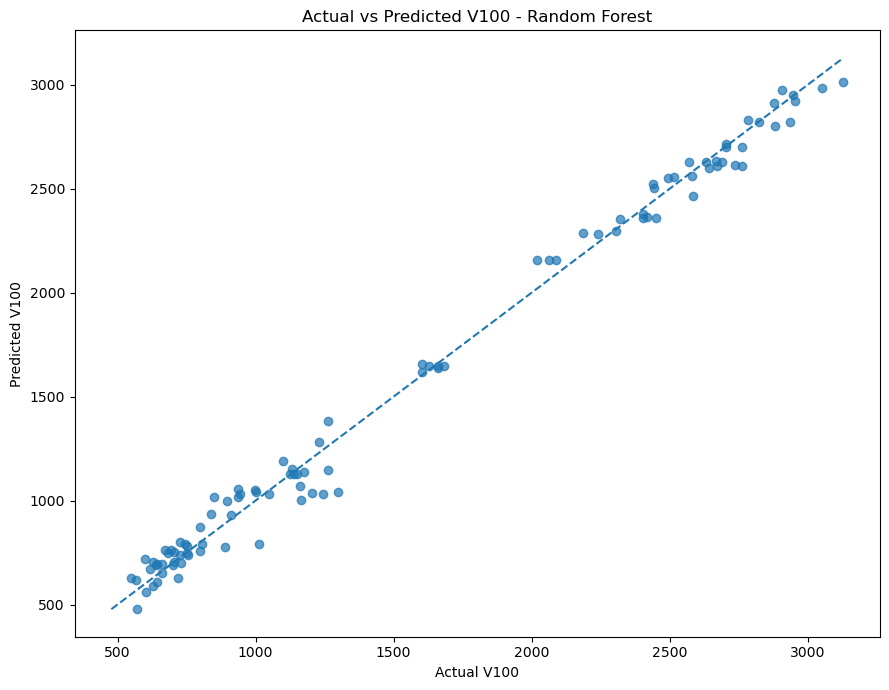

In [46]:
plt.figure(figsize=(9, 7))

plt.scatter(
    y_test,
    rf_pred,
    alpha=0.7
)

min_value = min(
    y_test.min(),
    rf_pred.min()
)

max_value = max(
    y_test.max(),
    rf_pred.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual V100")
plt.ylabel("Predicted V100")

plt.title("Actual vs Predicted V100 - Random Forest")

plt.tight_layout()
plt.show()

V100 prediction error

In [47]:
v100_evaluation = pd.DataFrame({
    "Actual V100": y_test.values,
    "Predicted V100": rf_pred
})

v100_evaluation["Error"] = (
    v100_evaluation["Actual V100"]
    - v100_evaluation["Predicted V100"]
)

v100_evaluation["Absolute Error"] = (
    v100_evaluation["Error"].abs()
)

display(v100_evaluation.head(20))

,Actual V100,Predicted V100,Error,Absolute Error
0,1246,1030.966681,215.033319,215.033319
1,662,694.034175,-32.034175,32.034175
2,2494,2551.628325,-57.628325,57.628325
3,2935,2820.943278,114.056722,114.056722
4,936,1053.731308,-117.731308,117.731308
5,2240,2281.397675,-41.397675,41.397675
6,630,591.314388,38.685612,38.685612
7,945,1030.676480,-85.676480,85.676480
8,549,626.854562,-77.854562,77.854562
9,1101,1192.419659,-91.419659,91.419659


In [48]:
# ========================================================
# Independent V100 Model Training & Saving
# ========================================================

# Explicitly select V100 as the target
target_v100 = "V100"

# Remove rows with missing V100 target values
data_v100 = df.dropna(subset=[target_v100]).copy()

# Exclude all six target columns to prevent target leakage
target_columns = ["V100", "V200", "E100", "E200", "BD100", "BD200"]
features_v100 = [col for col in features_100 if col not in target_columns]

# Dedicated feature DataFrame and target Series
X_v100 = data_v100[features_v100]
y_v100 = data_v100[target_v100]

# Split into training and held-out test data
X_train_v100, X_test_v100, y_train_v100, y_test_v100 = train_test_split(
    X_v100,
    y_v100,
    test_size=0.20,
    random_state=42
)

# Independent Random Forest pipeline using existing hyperparameters and preprocessing
v100_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=15,
        min_samples_split=3,
        random_state=42,
        n_jobs=-1
    ))
])

# Fit only on V100 training data
v100_model.fit(X_train_v100, y_train_v100)

# Save model to specified path
save_path = "../models/v100_random_forest.pkl"
os.makedirs(os.path.dirname(save_path), exist_ok=True)
joblib.dump(v100_model, save_path)

# Also save to repo root models/ if executing from repo root
if os.path.exists("models") and os.path.isdir("models"):
    joblib.dump(v100_model, "models/v100_random_forest.pkl")

print("V100 model trained and saved successfully!")


V100 model trained and saved successfully!


Test a new prediction

In [49]:
sample = df[features_v100].iloc[[0]]

actual = df["V100"].iloc[0]

prediction = v100_model.predict(sample)[0]

print("Actual V100:", actual)
print("Predicted V100:", round(prediction, 2))
print(
    "Absolute Error:",
    round(abs(actual - prediction), 2)
)


Actual V100: 1150
Predicted V100: 1127.94
Absolute Error: 22.06


In [ ]:
# ========================================================
# Validate Saved V100 Model
# ========================================================

# 1. Reload the model using Joblib
load_path = "../models/v100_random_forest.pkl"
if not os.path.exists(load_path) and os.path.exists("models/v100_random_forest.pkl"):
    load_path = "models/v100_random_forest.pkl"

loaded_v100_model = joblib.load(load_path)
print(f"Loaded model successfully from: {load_path}")

# 2. Confirm accepted input features
fitted_features = list(loaded_v100_model.feature_names_in_)
print("\nExpected features:", features_v100)
print("Fitted features:  ", fitted_features)
assert fitted_features == features_v100, "Fitted features do not match expected V100 features!"

# 3. Generate predictions for held-out test data
v100_test_preds = loaded_v100_model.predict(X_test_v100)

# 4. Calculate MAE, RMSE, and R2 against actual V100 values
mae = mean_absolute_error(y_test_v100, v100_test_preds)
mse = mean_squared_error(y_test_v100, v100_test_preds)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_v100, v100_test_preds)

print("\nReloaded V100 Model Validation Metrics:")
print("---------------------------------------")
print(f"MAE : {mae:.4f}")
print(f"MSE : {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²  : {r2:.4f}")

# 5. Compare with notebook's original V100 evaluation results
print("\nComparison with Original V100 Evaluation:")
print(f"Original MAE : {rf_mae:.4f}  |  Reloaded MAE : {mae:.4f}")
print(f"Original RMSE: {rf_rmse:.4f}  |  Reloaded RMSE: {rmse:.4f}")
print(f"Original R²  : {rf_r2:.4f}  |  Reloaded R²  : {r2:.4f}")

# 6. Verify missing feature values are handled by preprocessing pipeline
sample_with_nan = X_test_v100.copy().iloc[[0]]
sample_with_nan.loc[sample_with_nan.index[0], "BC"] = np.nan
nan_pred = loaded_v100_model.predict(sample_with_nan)[0]
print(f"\nMissing feature test (NaN in BC): Prediction = {nan_pred:.2f} (handled successfully)")


Loaded model successfully from: ../models/v100_random_forest.pkl

Expected features: ['Cartridge', 'Type', 'Weight', 'BC', 'V0']
Fitted features:   ['Cartridge', 'Type', 'Weight', 'BC', 'V0']

Reloaded V100 Model Validation Metrics:
---------------------------------------
MAE : 63.2964
MSE : 6512.7899
RMSE: 80.7019
R²  : 0.9912

Comparison with Original V100 Evaluation:
Original MAE : 63.2964  |  Reloaded MAE : 63.2964
Original RMSE: 80.7019  |  Reloaded RMSE: 80.7019
Original R²  : 0.9912  |  Reloaded R²  : 0.9912

Missing feature test (NaN in BC): Prediction = 1030.97 (handled successfully)
